In [1]:
import numpy as np
import matplotlib as plt
import random as rn
import math

In [ ]:
np.random.permutation(255)

In [14]:
sched = np.array([227, 234,  0, 164, 130, 217,  48, 163, 169,  22, 162,  91, 150,
       210, 236, 202, 114, 106,  33, 206,  75,   20,  74,  61, 156, 118,
       248, 170, 102,  60, 208,  17, 249,   2, 146, 107, 103,  82,  30,
       224,  66,  79, 178,  78, 157,  50, 228,  57,  38, 215, 113, 126,
        54,  69, 242, 133,  95,  76, 189, 251,  58, 151, 204, 159, 104,
       155, 172,  98, 167, 152,  31, 190,  44, 135, 154,  68,  34, 235,
       193, 137,  55, 197, 225, 149, 232,  52, 165,  67, 132, 179, 116,
       101, 115, 201, 124, 229, 240, 187,  25,  26,  63,  87, 188,  39,
        90, 160, 131,  15, 153, 220, 171,  51, 253,  18, 147, 176,  43,
         6, 196, 161, 239,  27,  11, 134, 226, 185, 212,   3,  73, 122,
        23,  24, 219, 252, 246,  88,  16, 254, 237, 241,  84, 123, 250,
        62,  81, 148,   7,  89, 109, 221, 216, 243,  97, 218, 200, 245,
        70, 233, 199, 120,   9,  64,  35, 166,  36, 183,  72,  56,   1,
       175,  42, 186, 213, 121,  28, 244, 129, 173, 184,  93, 100,  96,
       174, 105, 203, 125, 198, 211, 139,  94,  65,   8, 177, 182,  59,
        71, 230,  86, 145, 181,  77,  99, 138, 207, 136, 238,  19,  45,
       214,  12, 127, 205, 194,  49,  37, 222, 143,  41, 128, 112, 111,
       195,  46,  92,   4,  32,  21,  83,  80,  40, 158, 231, 117,  47,
       191, 108,  29, 144, 168, 192, 110, 247,   5, 223,  13, 141,  53,
       209, 119, 140,  10, 142,  14, 180,  85])


In [15]:
sched_out = np.zeros(10)

In [16]:
i=0
j=0

for i in range(10):
        i = (1 + i) % 256
        j = (sched[i] + j) % 256
        
        tmp = sched[j]
        sched[j] = sched[i]
        sched[i] = tmp
        
        sched_out[i-1] = sched[(sched[i] + sched[j]) % 256]

In [17]:
sched_out

array([175.,   0., 199.,  13., 169.,  72., 228., 227.,  70.,  46.])

## Bias in RC4 Stream generator

> ### Let a RC4 output $\rightarrow$ 5, 0, 0, 23, ..., 7, 32, 11, 11, ..., 0, 0 ...

> ### Let a ideal random generator $\rightarrow$ 83, 7, 69, 0, 0, ..., 42, 4, 13, ..., 27, 8 ...

### Fluher- Martin Theorem:
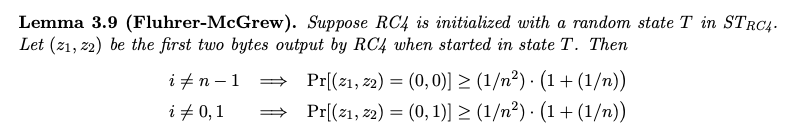

## Bias in RC4 Stream generator (Continue)
> ### Let a RC4 output $\rightarrow$ 5, 0, 0, 23, ..., 7, 32, 11, 11, ..., 0, 0 ...

> ### Let a ideal random generator $\rightarrow$ 83, 7, 69, 0, 0, ..., 42, 4, 13, ..., 27, 8 ...

### In ideal random string$\rightarrow$ Probability of occurance of (......, x, y, ..., ... )$ \\ = P[x] \times \ P[y] = \frac{1}{n} \times \frac{1}{n} = \frac{1}{n^2} $

In [73]:
sched.index(167)

1

In [64]:
g1 = stream_generation(sched)

In [74]:
[next(stream_generation(sched)) for i in range(2)]

[52, 239]

In [40]:
list(stream_generation(sched))

KeyboardInterrupt: 

In [39]:
int(0x7f8cbc581228)

140242432037416

In [4]:
def encrypt(text, key):
    text = [ord(char) for char in text]
    key = [ord(char) for char in key]
    
    sched = key_scheduling(key)
    key_stream = stream_generation(sched)
    
    ciphertext = ''
    for char in text:
        enc = str(hex(char ^ next(key_stream))).upper()
        ciphertext += (enc)
        
    return ciphertext

In [5]:
def decrypt(ciphertext, key):
    ciphertext = ciphertext.split('0X')[1:]
    ciphertext = [int('0x' + c.lower(), 0) for c in ciphertext]
    key = [ord(char) for char in key]
    
    sched = key_scheduling(key)
    key_stream = stream_generation(sched)
    
    plaintext = ''
    for char in ciphertext:
        dec = str(chr(char ^ next(key_stream)))
        plaintext += dec
    
    return plaintext

In [6]:
if __name__ == '__main__':
    ed = input('Enter E for Encrypt, or D for Decrypt: ').upper()
    if ed == 'E':
        plaintext = input('Enter your plaintext: ')
        key = input('Enter your secret key: ')
        result = encrypt(plaintext, key)
        print('Result: ')
        print(result)
    elif ed == 'D': 
        ciphertext = input('Enter your ciphertext: ')
        key = input('Enter your secret key: ')
        result = decrypt(ciphertext, key)
        print('Result: ')
        print(result)
    else:
        print('Error in input - try again.')

Enter E for Encrypt, or D for Decrypt: E
Enter your plaintext: Manish
Enter your secret key: open sesame
Result: 
0XE90X4F0X690X170XA10X4C
